<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ICA Recovery Correlations:
[np.float64(0.8334304358478551), np.float64(0.878425155462078), np.float64(0.6937074970571117)]

PCA Recovery Correlations:
[np.float64(0.9102230357895943), np.float64(0.8816444565611642), np.float64(0.7983375278600463)]


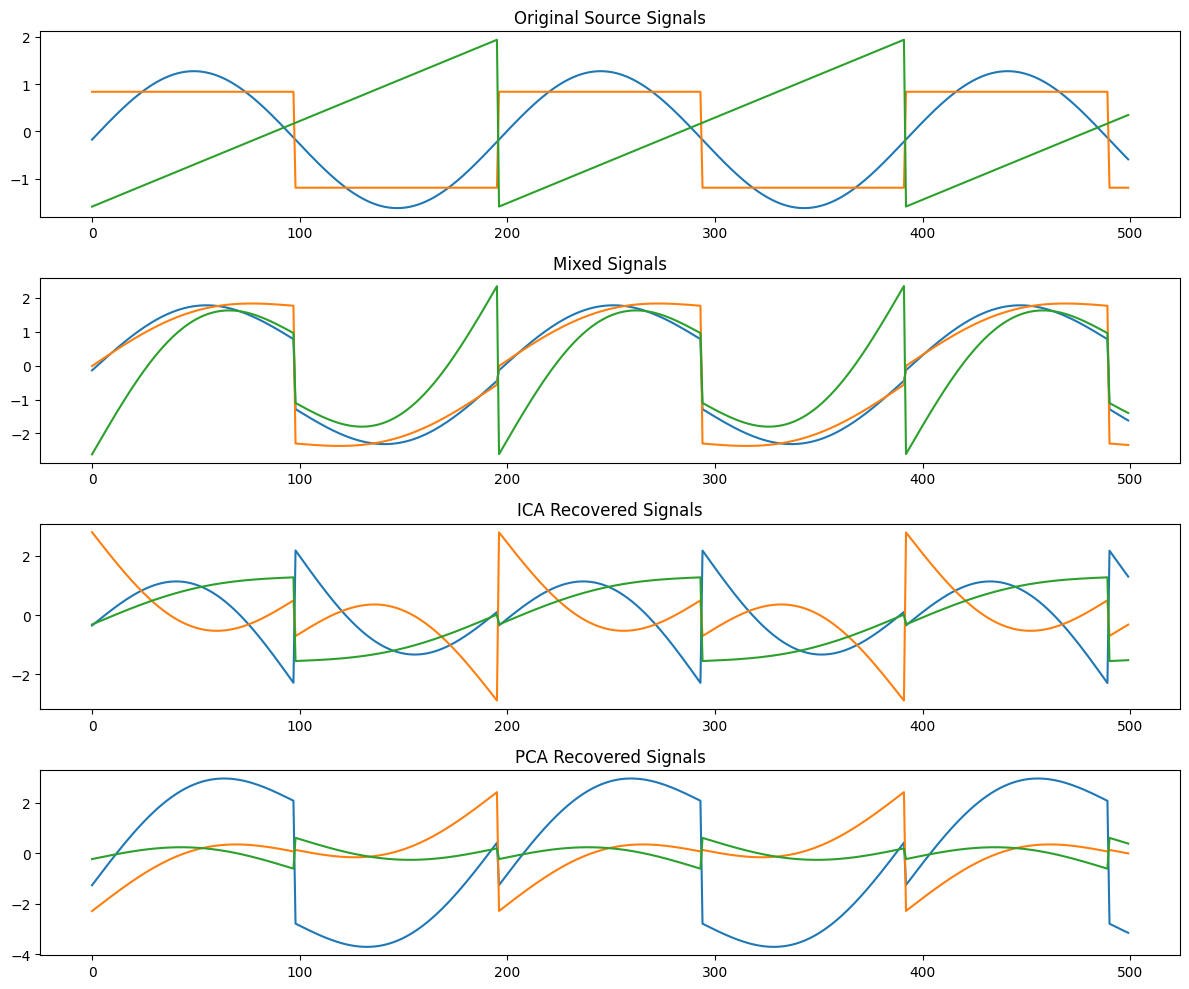

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import sawtooth, square
from sklearn.decomposition import FastICA, PCA

# Generate three source signals
np.random.seed(42)

time = np.linspace(0, 8, 500)

S = np.c_[
    np.sin(2 * time),
    square(2 * time),
    sawtooth(2 * time)
]

# Standardise sources
S = (S - S.mean(axis=0)) / S.std(axis=0)

# Mix signals
A = np.array([
    [1, 1, 0.5],
    [0.5, 2, 1],
    [1.5, 1, 2]
])

X = S @ A.T

# Apply FastICA
ica = FastICA(n_components=3, random_state=42,
              max_iter=1000, tol=0.001)
S_ica = ica.fit_transform(X)

# Apply PCA
pca = PCA(n_components=3)
S_pca = pca.fit_transform(X)

# Calculate correlations
def correlation_score(original, recovered):
    scores = []
    for i in range(3):
        best = max(
            abs(np.corrcoef(original[:, i], recovered[:, j])[0, 1])
            for j in range(3)
        )
        scores.append(best)
    return scores

print("ICA Recovery Correlations:")
print(correlation_score(S, S_ica))

print("\nPCA Recovery Correlations:")
print(correlation_score(S, S_pca))

# Plot signals
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

axes[0].plot(S)
axes[0].set_title("Original Source Signals")

axes[1].plot(X)
axes[1].set_title("Mixed Signals")

axes[2].plot(S_ica)
axes[2].set_title("ICA Recovered Signals")

axes[3].plot(S_pca)
axes[3].set_title("PCA Recovered Signals")

plt.tight_layout()
plt.show()